In [1]:
import pandas as pd
import numpy as np

In [2]:
df=pd.read_csv('Churn_Modelling.csv')
df

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [3]:
# handling some missing value
df.isnull().sum()                   # no any null value

# check duplicate value
df.duplicated().sum()               # no any duplicate value 

# remove some unwanted col
df.drop(columns=['RowNumber','CustomerId','Surname'],inplace=True)

df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [4]:
# check total existed
print(df['Exited'].value_counts())
print(df['Geography'].value_counts())
print(df['Gender'].value_counts())

Exited
0    7963
1    2037
Name: count, dtype: int64
Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64
Gender
Male      5457
Female    4543
Name: count, dtype: int64


In [5]:
# DO some Encoding using pandas
df=pd.get_dummies(df,columns=['Geography','Gender'],drop_first=True)
df.head()


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False


In [6]:
# create x and y
x=df.drop(columns=['Exited'])
y=df['Exited']

# now do train test split
from sklearn.model_selection import train_test_split

xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.2,random_state=42)

xtrain.shape,xtest.shape

((8000, 11), (2000, 11))

In [7]:
# do some scaling beacuase some valuee are to high
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()

xtrain_scaled=scaler.fit_transform(xtrain)
xtest_scaled=scaler.transform(xtest)

xtrain_scaled

array([[ 0.35649971, -0.6557859 ,  0.34567966, ..., -0.57946723,
        -0.57638802,  0.91324755],
       [-0.20389777,  0.29493847, -0.3483691 , ...,  1.72572313,
        -0.57638802,  0.91324755],
       [-0.96147213, -1.41636539, -0.69539349, ..., -0.57946723,
         1.73494238,  0.91324755],
       ...,
       [ 0.86500853, -0.08535128, -1.38944225, ..., -0.57946723,
        -0.57638802, -1.09499335],
       [ 0.15932282,  0.3900109 ,  1.03972843, ..., -0.57946723,
        -0.57638802,  0.91324755],
       [ 0.47065475,  1.15059039, -1.38944225, ...,  1.72572313,
        -0.57638802,  0.91324755]], shape=(8000, 11))

In [ ]:
# now create model
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [22]:
# create model
model=Sequential()

# now add layer start with 2 hidden layer
model.add(Dense(11,activation='sigmoid',input_dim=11))     # input ghenar ahe n he layer ter mention kara lagte
model.add(Dense(11,activation='sigmoid'))     

# output layer
model.add(Dense(1,activation='sigmoid'))     

# compile the model
model.compile(loss='binary_crossentropy',optimizer='Adam',metrics=['accuracy'])

# train the model
history=model.fit(xtrain_scaled,ytrain,epochs=10,validation_split=0.2)

c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7934 - loss: 0.5133 - val_accuracy: 0.7987 - val_loss: 0.4882
Epoch 2/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7934 - loss: 0.4872 - val_accuracy: 0.7987 - val_loss: 0.4664
Epoch 3/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7934 - loss: 0.4651 - val_accuracy: 0.7987 - val_loss: 0.4425
Epoch 4/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7947 - loss: 0.4469 - val_accuracy: 0.8094 - val_loss: 0.4292
Epoch 5/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8048 - loss: 0.4377 - val_accuracy: 0.8125 - val_loss: 0.4228
Epoch 6/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8067 - loss: 0.4336 - val_accuracy: 0.8200 - val_loss: 0.4200
Epoch 7/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8087 - loss: 0.4315 - val_accuracy: 0.8181 - val_loss: 0.4186
Epoch 8/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8070 - loss: 0.4303 - val_accuracy: 0.

In [17]:
# check model structure
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            12 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 830 (3.25 KB)

 Trainable params: 276 (1.08 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 554 (2.17 KB)

In [16]:
# get weigths from layers
model.layers[0].get_weights()
model.layers[1].get_weights()

[array([[-0.04036083, -0.01037601,  0.46762353, -0.18639003, -0.0153931 ,
          0.49083415,  0.64550865, -0.20645595, -0.6599253 ,  0.69429797,
         -0.39631587],
        [-0.23197018, -0.44844493,  0.29676488, -0.12283576,  0.68694055,
          0.51399934, -0.04066743, -0.7692907 , -0.45836797,  0.0771163 ,
         -0.7714624 ],
        [-0.6151784 , -0.54324293,  0.7215593 , -0.09731309,  0.02124847,
          0.87275237,  0.27421612,  0.08790201, -0.10435537,  0.7511828 ,
         -0.20203635],
        [-0.26221085, -0.7562494 ,  0.42628834,  0.62252057,  0.4484588 ,
         -0.04832592,  0.40296215, -0.35097042,  0.11210576, -0.12551668,
         -0.35350275],
        [-0.49214894, -0.6766252 ,  0.29616708,  0.49010363,  0.6114504 ,
          0.04181395,  0.01245827, -0.08712161, -0.34491283,  0.17592642,
         -0.2963098 ],
        [ 0.1435818 , -0.03303974,  0.7391316 ,  0.5890074 ,  0.26122665,
          0.6324807 ,  0.86269176, -0.09660108, -0.2707565 ,  0.1590595

In [21]:
# take prediction 
ypred=model.predict(xtest_scaled)
ypred

# the prediction is in probability but we want value so we converted it into 0 or 1 using threshold=0.5
y_pred=np.where(ypred>0.5,1,0)
print(y_pred)

# check accuracy 
from sklearn.metrics import accuracy_score

print(accuracy_score(ytest,y_pred))

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
[[0]
 [0]
 [0]
 ...
 [0]
 [0]
 [0]]
0.822


In [24]:
# visualize it 
import matplotlib.pyplot as plt

history.history

{'accuracy': [0.7934374809265137,
  0.7934374809265137,
  0.7934374809265137,
  0.7946875095367432,
  0.8048437237739563,
  0.8067187666893005,
  0.8087499737739563,
  0.8070312738418579,
  0.8090624809265137,
  0.8095312714576721],
 'loss': [0.5133470296859741,
  0.487207293510437,
  0.46511727571487427,
  0.44693633913993835,
  0.43773260712623596,
  0.43361151218414307,
  0.4314684569835663,
  0.4302636682987213,
  0.42875421047210693,
  0.4272959530353546],
 'val_accuracy': [0.7987499833106995,
  0.7987499833106995,
  0.7987499833106995,
  0.809374988079071,
  0.8125,
  0.8199999928474426,
  0.8181250095367432,
  0.8212500214576721,
  0.8199999928474426,
  0.8243749737739563],
 'val_loss': [0.4881545603275299,
  0.46638789772987366,
  0.4425404667854309,
  0.4292106628417969,
  0.4227532148361206,
  0.41995877027511597,
  0.4186205267906189,
  0.41723957657814026,
  0.41615527868270874,
  0.41458484530448914]}

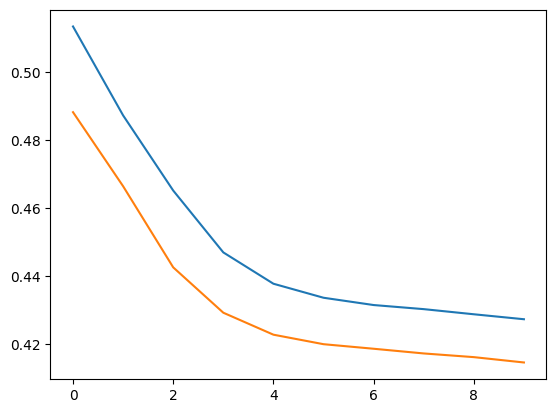

In [25]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

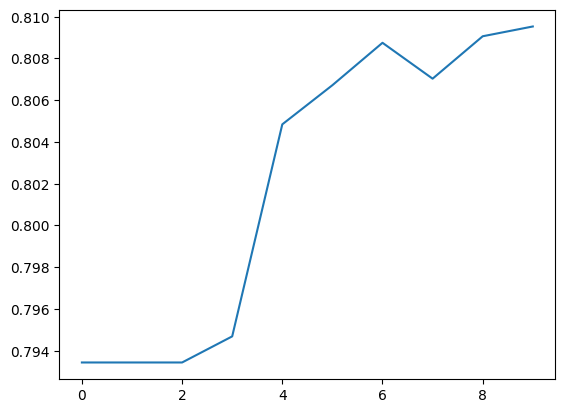

In [26]:
plt.plot(history.history['accuracy'])